In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pre_processing import pre_process, json_decode


sns.set_palette("hsv_r")

# This affects things like the size of the labels, lines, and other elements of the plot, but not the overall style. 
# The base context is “notebook”, and the other contexts are “paper”, “talk”, and “poster”, which are version of 
# the notebook parameters scaled by .8, 1.3, and 1.6, respectively.
sns.set_context("talk")

%config Inline.figure_format = 'retina'
%matplotlib inline

## Read in Data 

In [4]:
# File paths for each experimental condition (can contain multiple subjects/files) 
file_paths_baseline = [
    "../data/csv_files/06_baseline.csv", 
    "../data/csv_files/07_baseline.csv", 
    "../data/csv_files/08_baseline.csv", 
    "../data/csv_files/09_baseline.csv"
]

file_paths_repulse = [
    "../data/csv_files/06_repulse.csv", 
    "../data/csv_files/07_repulse.csv", 
    "../data/csv_files/08_repulse.csv", 
    "../data/csv_files/09_repulse.csv"
]

file_paths_udl = [
    "../data/csv_files/06_udl.csv", 
    "../data/csv_files/07_udl.csv", 
    "../data/csv_files/08_udl.csv", 
    "../data/csv_files/09_udl.csv"
]

# Subject identifiers corresponding to the datasets
# Actual participants have randomly generated KinArm IDs
subject_list = ["105283198",    
                "263471501", 
                "145349743", 
                "23426115"]    

# Load CSV files & label condition
df_baseline_raw = pre_process(file_paths_baseline, subject_list)
df_baseline_raw['phase'] = 'baseline'

df_repulse_raw = pre_process(file_paths_repulse, subject_list)
df_repulse_raw['phase'] = 'repulse'

df_udl_raw = pre_process(file_paths_udl, subject_list)
df_udl_raw['phase'] = 'udl'

# Combine all conditions into a single dataset
df = pd.concat([df_baseline_raw, df_repulse_raw, df_udl_raw]).reset_index(drop=True)

# Add 5 to each subject ID (the 5 are from pilot data)
df["SN"] = df["SN"].astype(int) + 5

# Reset the trial number column that resets for each subject
df["TN"] = df.groupby("SN").cumcount() + 1
df

,SN,TN,target_angle,probe,feedback,reach_feedback,rt,mt,peak_vel,theta_40,theta_100,theta_pv,theta_end,Subject ID,phase
0,6,1,150,0,0,too slow,0.981,0.464,25.818030,1.189295,2.387589,2.448600,-1.025799,105283198,baseline
1,6,2,120,0,0,good reach,0.871,0.249,48.466082,29.837668,18.573214,10.839428,8.380231,105283198,baseline
2,6,3,60,0,0,good reach,0.854,0.180,61.085862,7.414602,9.312587,6.199882,6.154166,105283198,baseline
3,6,4,90,0,0,good reach,0.858,0.166,65.915359,11.858549,8.276782,5.940809,4.430736,105283198,baseline
4,6,5,240,0,0,good reach,0.864,0.217,48.085023,3.962629,4.479889,3.599733,1.401127,105283198,baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6875,9,1716,60,0,0,good reach,1.662,0.186,56.829438,9.004444,4.788041,3.490402,1.584063,23426115,udl
6876,9,1717,60,0,0,good reach,0.859,0.181,59.059576,1.617547,-0.201720,-0.963340,-2.450001,23426115,udl
6877,9,1718,60,0,0,too early,0.467,0.182,12.494591,5.055926,2.050810,15.010387,15.010387,23426115,udl
6878,9,1719,60,0,0,good reach,0.898,0.177,59.721747,3.318180,1.429298,1.006351,0.743306,23426115,udl


## Define Functions 

In [5]:
# function to unpack repeated target value from series
# WE HAVENT USE THIS ONE YET.. copied from Jeremy's analysis script
def find_rep(group):
    vals = group['Repeated_Target'].iloc[0]
    return vals[1:4]   


def N_finder(group, N_minus_targ):
    
    # Find trials where N-1 had the specified target
    N_trial_num = (group.loc[group['target_angle'] == N_minus_targ,'TN'] + 1)

    # Return trial N
    N_df = group.loc[group['TN'].isin(N_trial_num)]
    return N_df


def calculate_se_index(df, y_col):
    """
    calculate the sequential effect (SE) index per participant 
    POSITIVE SE Index = attractive bias (UDL)
    NEGATIVE SE Index = repulsive bias (REPULSE)

    parameters: 
    df : DataFrame; data to calculate SE index from
    y_col : str; column containing corrected bias

    output: 
    df with the SE index per participant 
    """
    negative_mean = df.loc[df["target_angle_diff"] < 0].groupby("SN")[y_col].mean()
    positive_mean = df.loc[df["target_angle_diff"] > 0].groupby("SN")[y_col].mean()

    return negative_mean - positive_mean 

def circ_dist(ang1, ang2):

    ang1rad = np.deg2rad(ang1)
    ang2rad = np.deg2rad(ang2)
    ang_dist = np.rad2deg(np.arctan2(np.sin(ang1rad), np.cos(ang2rad)))

    return ang_dist


## should probably create a function that determines the repeated target and changes all the targets to be centred around ZERO 

## Data Wrangling 

In [6]:
## Define epochs for each phase of the experiment (trial number ranges for each phase)
epochs = {
    'baseline': (1, 17),                # Baseline reaching
    'repulse':(17, 717),                # Main experiment block
    'repulse_clean':(117, 717),         # For repulse bias correctinon
    'udl_baseline_FB': (717, 787),      # Baseline reaching 
    'udl_baseline_noFB': (787, 857),    # For UDL bias corrrection  
    'udl':(857, 1721),                  # Main experiment block
    'udl_full':(717, 1721),             # including the baseline
}

# Central/repeated target angle for each participant
# Update this dictionary as new participants are added
central_target = {
    6: 150,
    7: 60,
    8: 120,
    9: 60
}

# Shift target angles so each participant's central target = 0°
for sn, central_angle in central_target.items():
    mask = df["SN"] == sn
    TA_rad_shift = df.loc[mask, "target_angle"] - central_angle
    df.loc[mask, "target_angle"] = circ_dist(TA_rad_shift, TA_rad_shift).round()

# Get target angle difference (delta target angle) values
df['target_angle_diff'] = pd.Series(pd.NA, index=df.index, dtype='Float64')
# NOTES:
# 1) CW is negative, CCW is positive 

mask = (df['TN'] >= epochs['repulse'][0]) & (df['TN'] < epochs['repulse'][1])
RadTAN1diff_repulse = np.deg2rad(df.loc[mask].groupby('SN')['target_angle'].diff(periods=1))
df.loc[mask,'target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_repulse), np.cos(RadTAN1diff_repulse)))

mask = (df['TN'] >= epochs['udl_full'][0]) & (df['TN'] < epochs['udl_full'][1])
RadTAN1diff_udl = np.deg2rad(df.loc[mask].groupby('SN')['target_angle'].diff(periods=1))
df.loc[mask,'target_angle_diff'] = np.rad2deg(np.arctan2(np.sin(RadTAN1diff_udl), np.cos(RadTAN1diff_udl)))

# Round 
df['target_angle_diff'] = df['target_angle_diff'].round().astype('Int64')


########################### CHANGED HERE #####################################################################

# Calculate bias for each participant (for REPULSE), which is used for bias correction in the UDL condition
bias_subset = (
    df.loc[(df['TN'] >= epochs['repulse_clean'][0]) & (df['TN'] < epochs['repulse_clean'][1]) & 
  #  (df['reach_feedback'] == 'good reach') & 
    (df['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_repulse'})
)
df = df.merge(bias_subset, on=['SN', 'target_angle'], how='left')
# Correct for target-level reach biases (for REPULSE) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df['theta_pv'] - df['bias_repulse'])
df['corrected_bias_repulse'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

# Calculate bias for each participant (for UDL), which is used for bias correction in the UDL condition
bias_subset = (
    df.loc[(df['TN'] >= epochs['udl_baseline_noFB'][0]) & (df['TN'] < epochs['udl_baseline_noFB'][1]) & 
    # (df['reach_feedback'] == 'good reach') & 
    (df['theta_pv'].abs() < 60)]
    .groupby(['SN', 'target_angle'], as_index=False)['theta_pv']
    .mean()
    .rename(columns={'theta_pv': 'bias_udl'})
)
df = df.merge(bias_subset, on=['SN', 'target_angle'], how='left')
# Correct for target-level reach biases (for UDL) by subtraction of mean hand angle to a target
RadCorrDiff = np.deg2rad(df['theta_pv'] - df['bias_udl'])
df['corrected_bias_udl'] = np.rad2deg(np.arctan2(np.sin(RadCorrDiff), np.cos(RadCorrDiff)))

## Trials by label (TOO FAST, TOO SLOW, TOO EARLY, GOOD REACH)

reach_feedback  SN     phase  good reach  too early  too fast  too slow
0                6  baseline        13.0        2.0       NaN       1.0
1                6   repulse       684.0       12.0       4.0       NaN
2                6       udl       979.0       19.0       NaN       6.0
3                7  baseline        14.0        2.0       NaN       NaN
4                7   repulse       638.0       46.0       2.0      14.0
5                7       udl       810.0      147.0       NaN      47.0
6                8  baseline        11.0        4.0       NaN       1.0
7                8   repulse       629.0       52.0       1.0      18.0
8                8       udl       897.0      102.0       3.0       2.0
9                9  baseline        15.0        1.0       NaN       NaN
10               9   repulse       678.0       19.0       NaN       3.0
11               9       udl       933.0       59.0       NaN      12.0


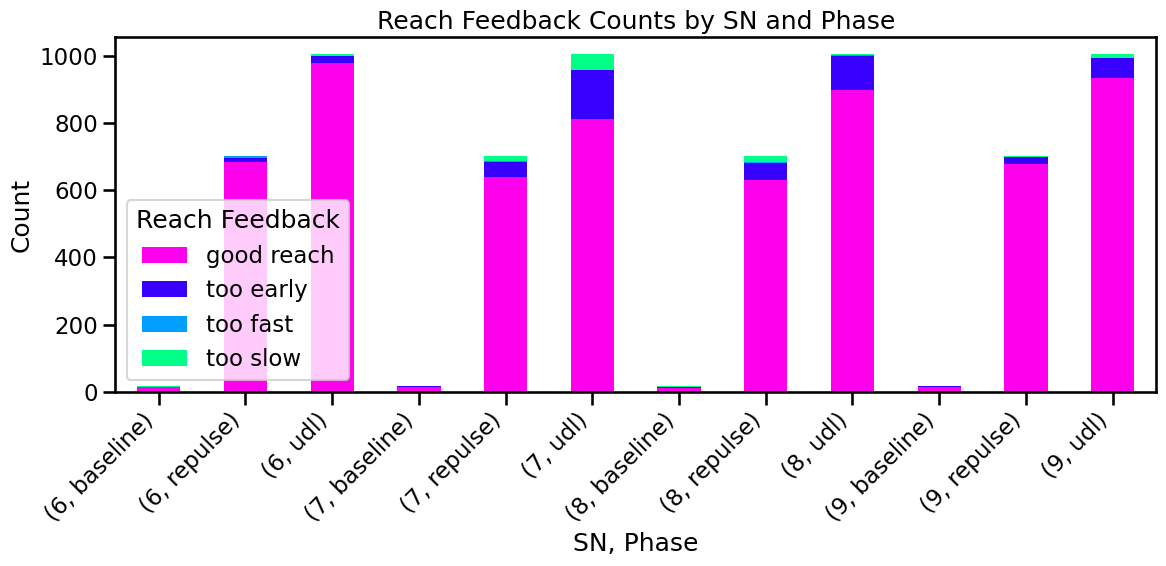

In [ ]:
reach_feedback_counts = (
    df.groupby(['SN', 'phase'])['reach_feedback']
      .value_counts()
      .unstack()
      .reset_index()
)

print(reach_feedback_counts)

plot_df = reach_feedback_counts.set_index(['SN', 'phase'])

plot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 6)
)

plt.xlabel('SN, Phase')
plt.ylabel('Count')
plt.title('Reach Feedback Counts by SN and Phase')
plt.legend(title='Reach Feedback')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# REPULSE: very lax filtering 

Text(0, 0.5, 'Corrected Bias')

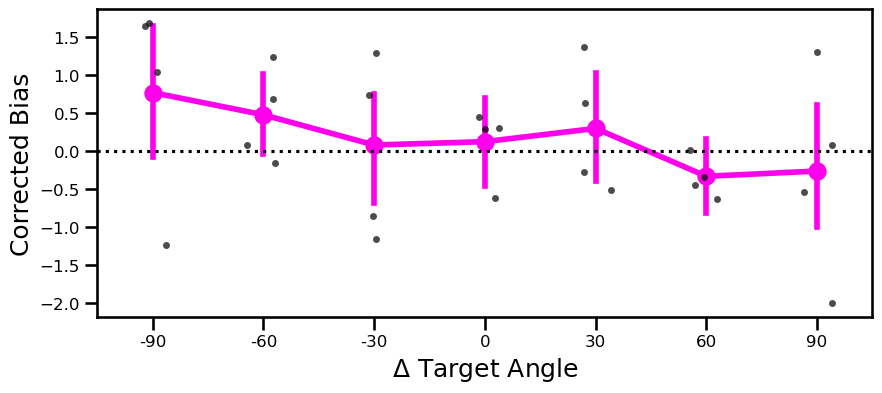

In [40]:
repulse_mask = (
    (df['TN'] >= epochs['repulse_clean'][0]) & (df['TN'] < epochs['repulse_clean'][1]) & 
    (df["target_angle_diff"].abs() <= 90) &
    (np.abs(df['theta_pv']) < 60)
)

df_repulse_lax = df.loc[repulse_mask].copy()

subject_means_repulse = (
    df_repulse_lax
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse']
    .mean()
    .reset_index()
)

fig2, ax2 = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_repulse_lax,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    # y='bias_repulse',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax2
)
sns.stripplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    # y='bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax2
)
ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')


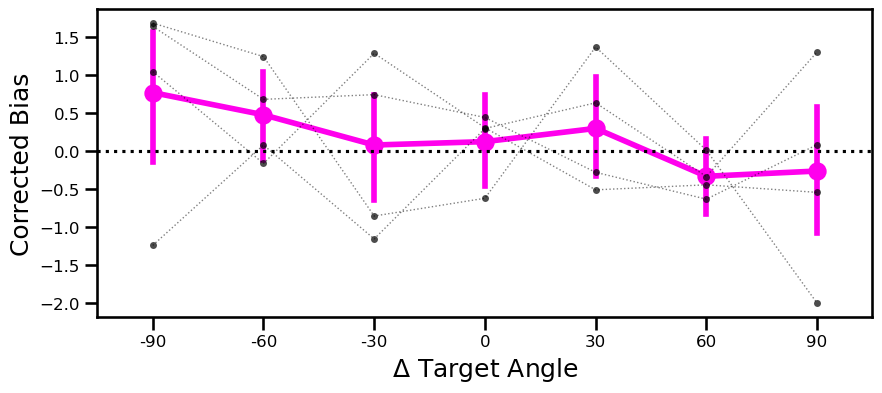

In [41]:
fig2, ax2 = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_repulse_lax,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax2
)

# Get x-category order for positioning the participant lines
x_order = sorted(df_repulse_lax['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_repulse.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax2.plot(
        x_positions,
        sub['corrected_bias_repulse'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_repulse,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax2
)

ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

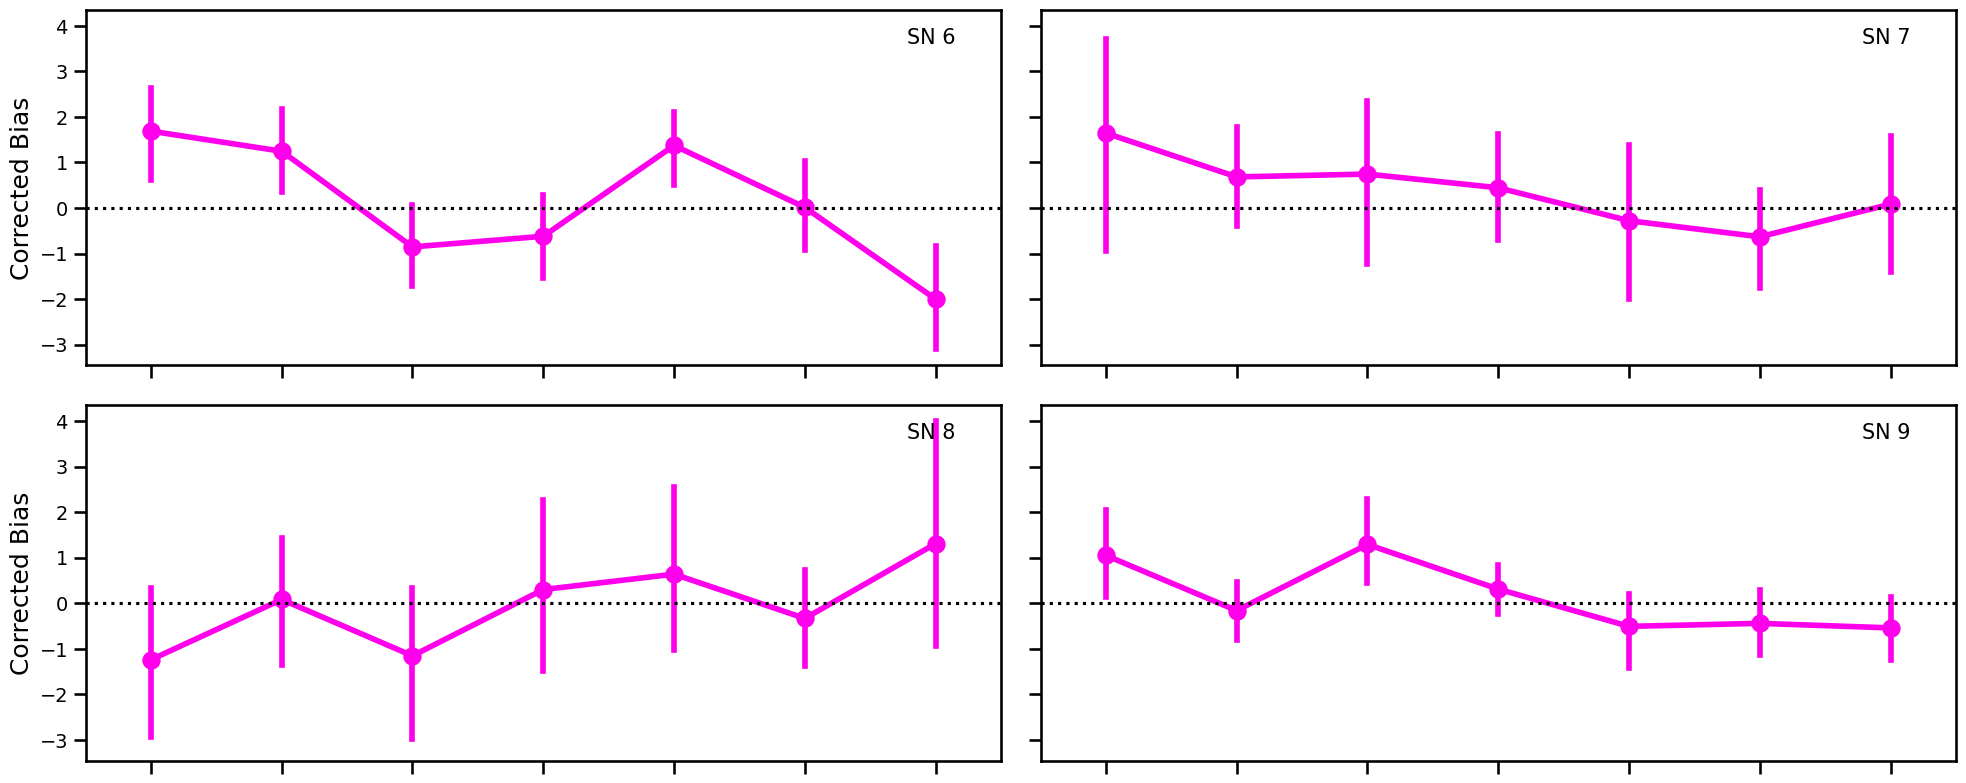

In [42]:
participants = sorted(df_repulse_lax['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_repulse_lax[df_repulse_lax['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_repulse',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

## REPULSE: remove when MT/RT is NA (i.e. dont cross 10cm/ slip from target )

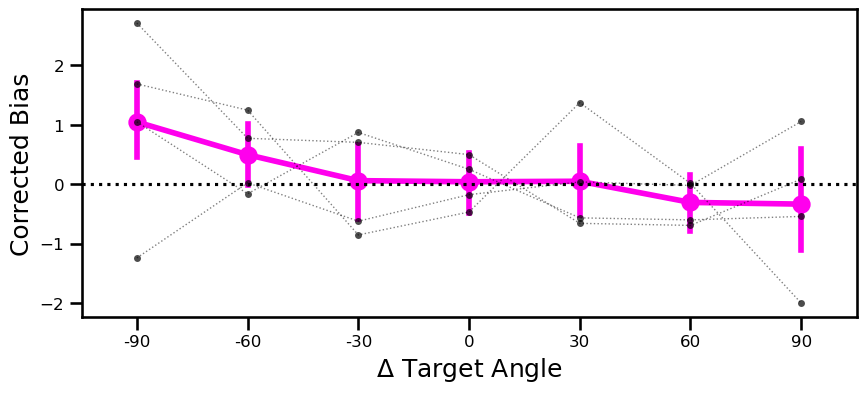

In [43]:
repulse_mask_medium = (
    (df['TN'] >= epochs['repulse_clean'][0]) &
    (df['TN'] < epochs['repulse_clean'][1]) &
    (df["target_angle_diff"].abs() <= 90) &
    (np.abs(df['theta_pv']) < 60) &
    (df['mt'].notna()) & 
    (df['rt'].notna())
)

df_repulse_medium = df.loc[repulse_mask_medium].copy()

subject_means_repulse_medium = (
    df_repulse_medium
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse']
    .mean()
    .reset_index()
)

fig2, ax2 = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_repulse_medium,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax2
)

# Get x-category order for positioning participant lines
x_order = sorted(df_repulse_medium['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_repulse_medium.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax2.plot(
        x_positions,
        sub['corrected_bias_repulse'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_repulse_medium,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax2
)

ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

## REPULSE: only good reach (STRICT)

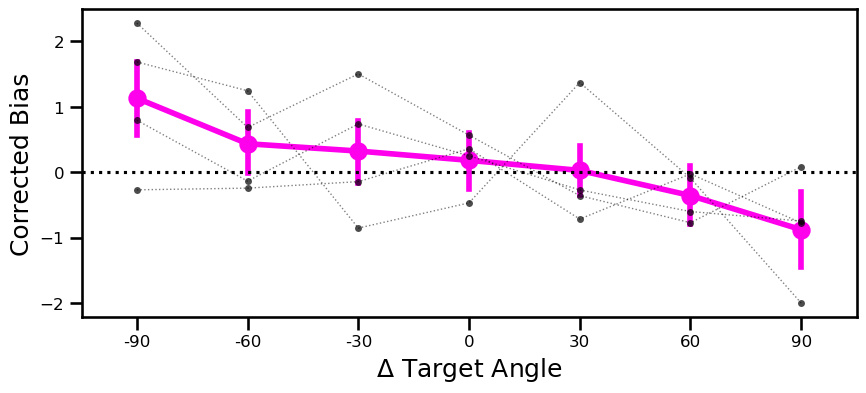

In [44]:
repulse_mask_strict = (
    (df['TN'] >= epochs['repulse_clean'][0]) &
    (df['TN'] < epochs['repulse_clean'][1]) &
    (df["target_angle_diff"].abs() <= 90) &
    (np.abs(df['theta_pv']) < 60) &
    (df['reach_feedback'] == 'good reach')
)

df_repulse_strict = df.loc[repulse_mask_strict].copy()

subject_means_repulse_strict = (
    df_repulse_strict
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_repulse']
    .mean()
    .reset_index()
)

fig2, ax2 = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_repulse_strict,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax2
)

# Get x-category order for positioning the participant lines
x_order = sorted(df_repulse_strict['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_repulse_strict.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax2.plot(
        x_positions,
        sub['corrected_bias_repulse'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_repulse_strict,
    x='target_angle_diff',
    y='corrected_bias_repulse',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax2
)

ax2.axhline(0, color='black', linestyle=':')
ax2.tick_params(axis='x', labelsize=12)
ax2.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

In [47]:
# All eligible trials in the repulse_clean epoch (between -90 to +90)
repulse_clean_all = df.loc[
    (df['TN'] >= epochs['repulse_clean'][0]) &
    (df['TN'] < epochs['repulse_clean'][1]) &
    (df["target_angle_diff"].abs() <= 90)
].copy()

filter_counts = pd.DataFrame({
    'totak repulse_clean': repulse_clean_all.groupby('SN').size(),
    'Lax': df_repulse_lax.groupby('SN').size(),
    'Medium': df_repulse_medium.groupby('SN').size(),
    'Strict': df_repulse_strict.groupby('SN').size()
}).fillna(0).astype(int)

filter_counts

,totak repulse_clean,Lax,Medium,Strict
SN,,,,
6,446,442,441,439
7,457,444,435,423
8,445,438,422,397
9,474,473,467,460


# Use Dependent Learning: very lax filtering

/var/folders/g6/bw3kklz96vl7dn2xz_xpz9440000gn/T/ipykernel_45677/3787877068.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(N_finder, N_minus_targ=0)


Text(0, 0.5, 'Corrected Bias')

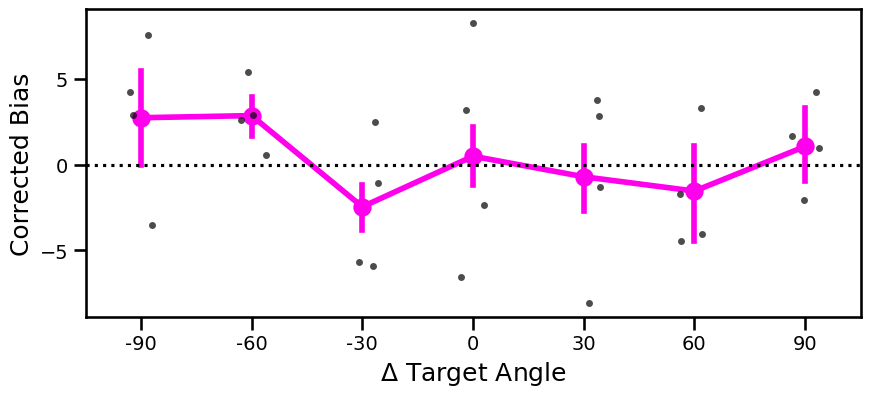

In [48]:
mask_udl_lax = (
    (df['TN'] >= epochs['udl'][0]) & (df['TN'] <= epochs['udl'][1]) &  
    (df['theta_pv'].abs() < 60)
)

df_udl_lax = df.loc[mask_udl_lax].copy()

df_udl_constrained_lax = (
    df_udl_lax
    .groupby('SN', as_index=False)
    .apply(N_finder, N_minus_targ=0)
    .reset_index(drop=True)
).copy()

df_udl_constrained_lax = df_udl_constrained_lax.loc[df_udl_constrained_lax['probe'] == 1]
subject_means = df_udl_constrained_lax.groupby(['SN', 'target_angle_diff'])['corrected_bias_udl'].mean().reset_index()

# plot graph for group level 
fig, ax = plt.subplots(figsize=(10,4))
sns.pointplot(
    data=df_udl_constrained_lax,
    x='target_angle_diff',
    y='corrected_bias_udl',
    estimator='mean',
    errorbar=('ci',95),
    #color='black',
    ax=ax
)

sns.stripplot(
    data=subject_means,
    x='target_angle_diff',
    y='corrected_bias_udl',
    color='black',
    alpha=0.7,
    jitter=0.15,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=14)
ax.tick_params(axis='y', labelsize=14)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias') 

# plt.savefig('withFB.png', dpi=600, bbox_inches='tight')

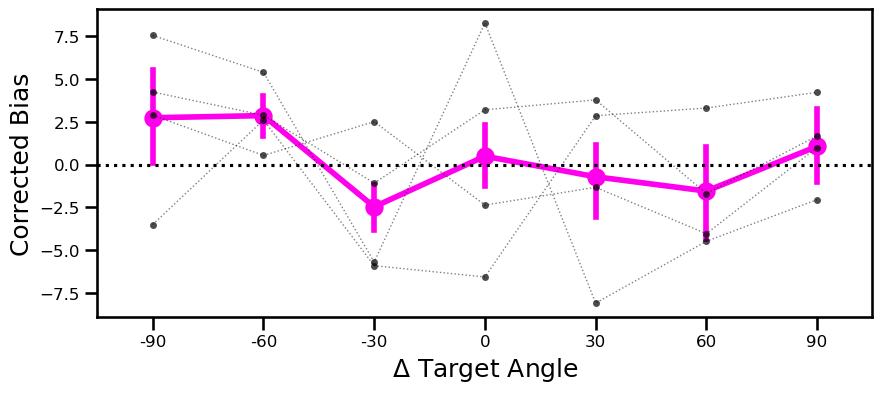

In [49]:
fig, ax = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_udl_constrained_lax,
    x='target_angle_diff',
    y='corrected_bias_udl',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax
)

# Get x-category order for positioning the participant lines
x_order = sorted(df_udl_constrained_lax['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax.plot(
        x_positions,
        sub['corrected_bias_udl'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means,
    x='target_angle_diff',
    y='corrected_bias_udl',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)
plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')
plt.show()

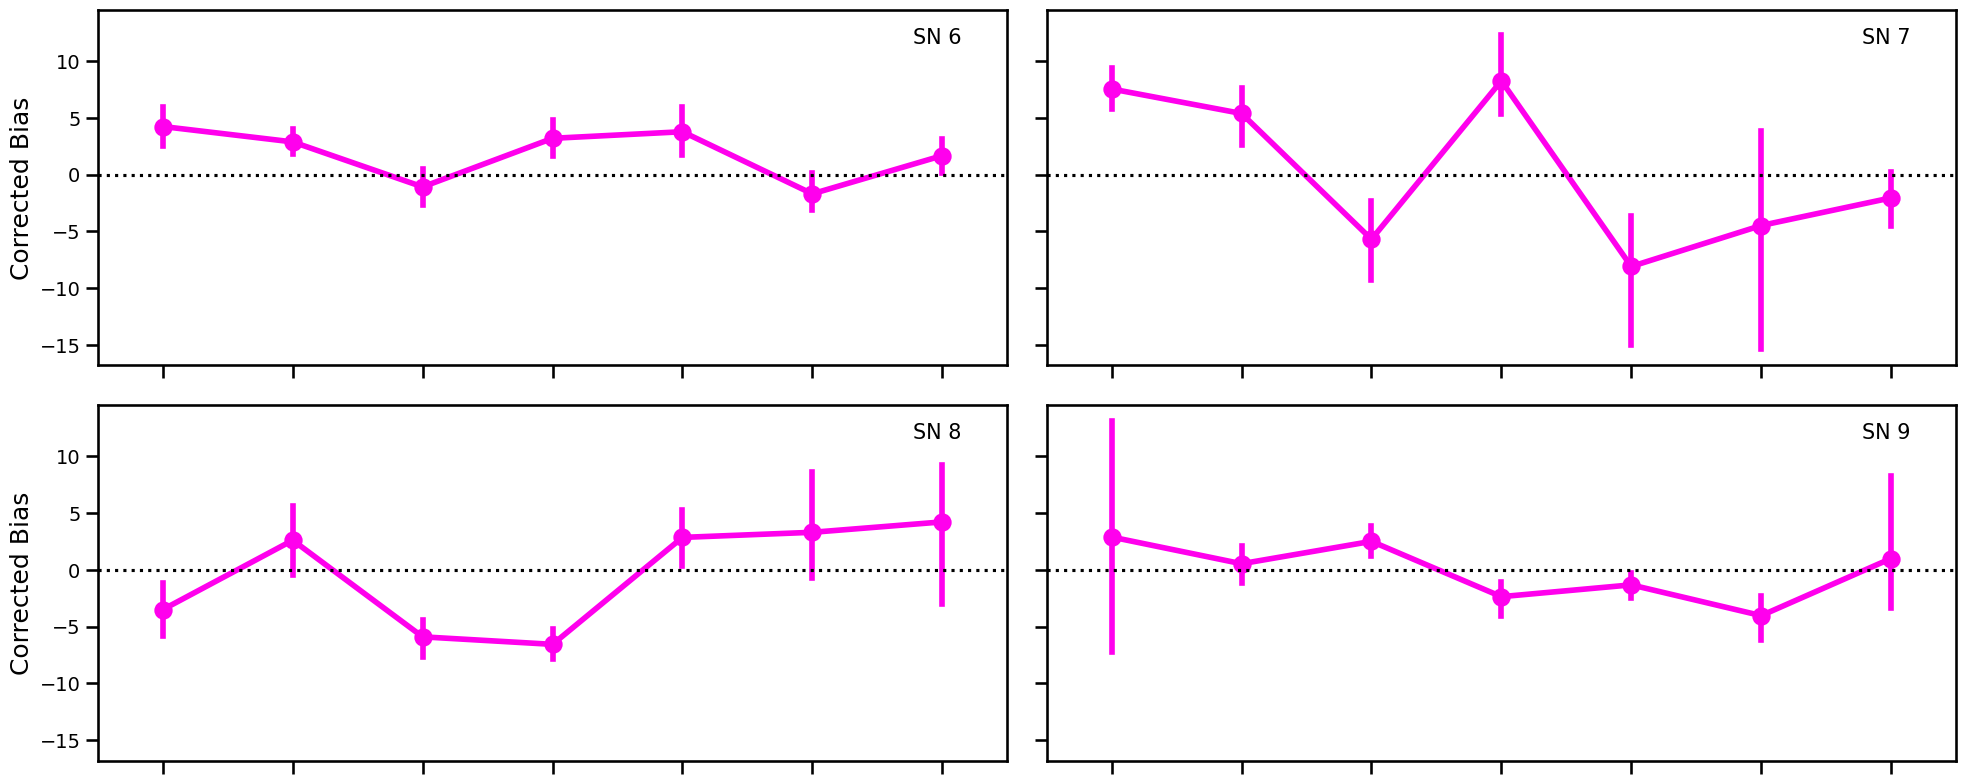

In [50]:
participants = sorted(df_udl_constrained_lax['SN'].unique())

fig, axes = plt.subplots(3, 2, figsize=(20, 12), sharex=True, sharey=True)
axes = axes.flatten()

for ax, subject_num in zip(axes, participants):

    sns.pointplot(
        data=df_udl_constrained_lax[df_udl_constrained_lax['SN'] == subject_num],
        x='target_angle_diff',
        y='corrected_bias_udl',
        estimator='mean',
        errorbar=('ci', 95),
        ax=ax
    )

    ax.axhline(0, color='black', linestyle=':')
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=14)

    ax.set_ylabel('Corrected Bias')
    ax.set_xlabel('')

    ax.text(
        0.95, 0.95,
        f'SN {subject_num}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=15
    )

# remove unused subplot(s)
for ax in axes[len(participants):]:
    ax.remove()

plt.tight_layout()
plt.show()

## UDL: remove when RT/MT is zero (med filter)

/var/folders/g6/bw3kklz96vl7dn2xz_xpz9440000gn/T/ipykernel_45677/3839092532.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(N_finder, N_minus_targ=0)


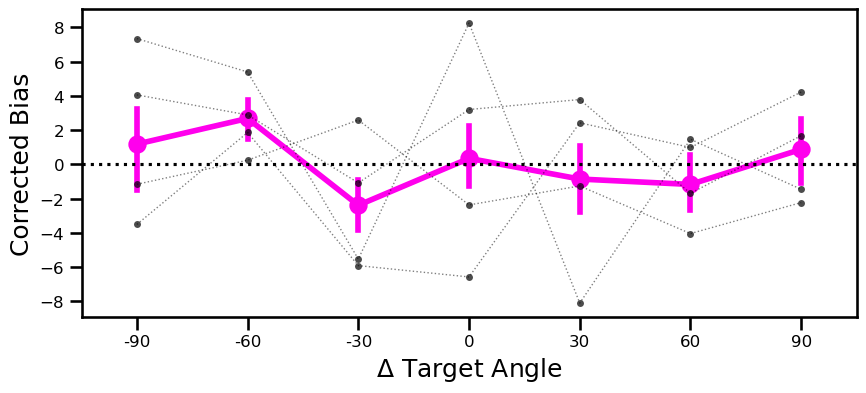

In [53]:
mask_udl_medium = (
    (df['TN'] >= epochs['udl'][0]) &
    (df['TN'] <= epochs['udl'][1]) &
    (df['theta_pv'].abs() < 60) &
    (df['mt'].notna()) & 
    (df['rt'].notna())
)

df_udl_medium = df.loc[mask_udl_medium].copy()

df_udl_constrained_medium = (
    df_udl_medium
    .groupby('SN', as_index=False)
    .apply(N_finder, N_minus_targ=0)
    .reset_index(drop=True)
).copy()

df_udl_constrained_medium = df_udl_constrained_medium.loc[
    df_udl_constrained_medium['probe'] == 1
]

subject_means_medium = (
    df_udl_constrained_medium
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_udl']
    .mean()
    .reset_index()
)

########################################################################

fig, ax = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_udl_constrained_medium,
    x='target_angle_diff',
    y='corrected_bias_udl',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax
)

# Get x-category order for positioning participant lines
x_order = sorted(df_udl_constrained_medium['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_medium.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax.plot(
        x_positions,
        sub['corrected_bias_udl'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_medium,
    x='target_angle_diff',
    y='corrected_bias_udl',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

## UDL: strict (only good reach)

/var/folders/g6/bw3kklz96vl7dn2xz_xpz9440000gn/T/ipykernel_45677/1248416296.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(N_finder, N_minus_targ=0)


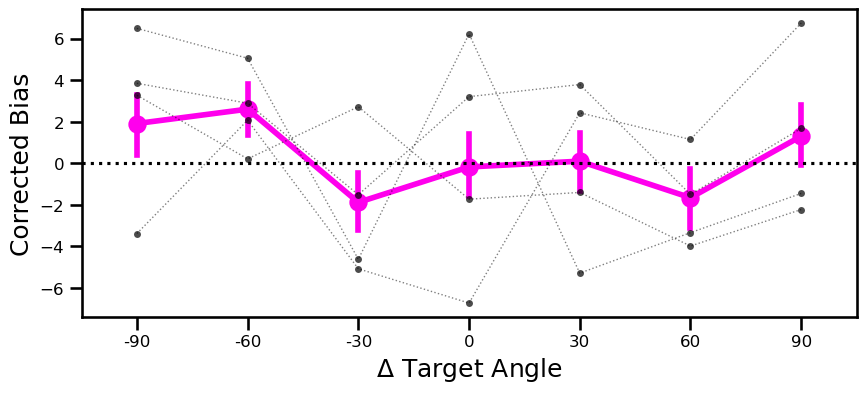

In [54]:
mask_udl_strict = (
    (df['TN'] >= epochs['udl'][0]) &
    (df['TN'] <= epochs['udl'][1]) &
    (df['theta_pv'].abs() < 60) &
    (df['reach_feedback'] == 'good reach')
)

df_udl_strict = df.loc[mask_udl_strict].copy()

df_udl_constrained_strict = (
    df_udl_strict
    .groupby('SN', as_index=False)
    .apply(N_finder, N_minus_targ=0)
    .reset_index(drop=True)
).copy()

df_udl_constrained_strict = df_udl_constrained_strict.loc[
    df_udl_constrained_strict['probe'] == 1
]

subject_means_strict = (
    df_udl_constrained_strict
    .groupby(['SN', 'target_angle_diff'])['corrected_bias_udl']
    .mean()
    .reset_index()
)


fig, ax = plt.subplots(figsize=(10,4))

# Group mean + 95% CI
sns.pointplot(
    data=df_udl_constrained_strict,
    x='target_angle_diff',
    y='corrected_bias_udl',
    estimator='mean',
    errorbar=('ci', 95),
    ax=ax
)

# Get x-category order for positioning participant lines
x_order = sorted(df_udl_constrained_strict['target_angle_diff'].unique())

# Connect each participant's dots
for sn, sub in subject_means_strict.groupby('SN'):
    sub = sub.sort_values('target_angle_diff')

    x_positions = [
        x_order.index(x)
        for x in sub['target_angle_diff']
    ]

    ax.plot(
        x_positions,
        sub['corrected_bias_udl'],
        color='black',
        linewidth=1,
        linestyle=':',
        alpha=0.5
    )

# Individual participant means
sns.stripplot(
    data=subject_means_strict,
    x='target_angle_diff',
    y='corrected_bias_udl',
    color='black',
    alpha=0.7,
    jitter=0,
    size=5,
    ax=ax
)

ax.axhline(0, color='black', linestyle=':')
ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.xlabel(r'$\Delta$ Target Angle')
plt.ylabel('Corrected Bias')

plt.show()

In [58]:
# get the count of probe trials 
mask_udl_total = (
    (df['TN'] >= epochs['udl'][0]) &
    (df['TN'] <= epochs['udl'][1])
)
df_udl_total = df.loc[mask_udl_total].copy()
df_udl_constrained_total = df_udl_total.loc[df_udl_total['probe'] == 1]

# make counts data frame
udl_filter_counts = pd.DataFrame({
    'Total UDL probe': df_udl_constrained_total.groupby('SN').size(),
    'Lax': df_udl_constrained_lax.groupby('SN').size(),
    'Medium': df_udl_constrained_medium.groupby('SN').size(),
    'Strict': df_udl_constrained_strict.groupby('SN').size()
}).fillna(0).astype(int)

udl_filter_counts

,Total UDL probe,Lax,Medium,Strict
SN,,,,
6,112,109,108,105
7,112,99,74,61
8,112,101,98,86
9,112,107,99,88
